In [12]:
from Things import Things

In [13]:
ids = [2, 3, 18760]
things = Things(ids)
coords = things.get_coordinates()
coords[2]

[[[9.9196439, 53.5638321],
  [9.9197085, 53.5637359],
  [9.9198219, 53.5635865],
  [9.9198451, 53.5635559],
  [9.9198231, 53.5634831],
  [9.9198481, 53.563453]],
 [[9.9197087, 53.563736],
  [9.9195566, 53.5639624],
  [9.9195566, 53.5639624],
  [9.919899, 53.5639529]],
 [[9.9197629, 53.5639568], [9.9198989, 53.5639531], [9.9200006, 53.5639497]]]

In [14]:
observs = things.get_tl_observations(things.ids, n_obsrvtns=3, phnTime=True)
for key, val in observs.items():
    print(f"Thing({key}) last {len(val)} observations:")
    for time, result in val:
        print(f"{time}: {result}")

Thing(2) last 3 observations:
2024-10-29T16:05:03Z: 1
2024-10-29T16:05:00Z: 2
2024-10-29T16:04:43Z: 3
Thing(3) last 3 observations:
2024-10-29T16:05:03Z: 1
2024-10-29T16:05:00Z: 2
2024-10-29T16:04:43Z: 3
Thing(18760) last 3 observations:
2024-10-29T16:04:42Z: 1
2024-10-29T16:04:39Z: 2
2024-10-29T16:04:03Z: 3


In [23]:
import pickle, os, time

cwd = os.getcwd()

locations_file = cwd + "/data/things_locations.pkl"
with open(locations_file, "rb") as file:
    things_locations = pickle.load(file)

keys = list(things_locations.keys())

n_keys = [10 * i for i in range(1, 11)]
avg_times = []
cycles = 100
for n in n_keys:
    start = time.time()
    for _ in range(cycles):
        things = Things(keys[:n])
        things._fetch_primary_signal_endpoint_ids()
    end = time.time()
    print(f"Done with n={n}")
    avg_time = (end - start) / cycles
    avg_times.append(avg_time)

print(avg_times)

Done with n=10
Done with n=20
Done with n=30
Done with n=40
Done with n=50
Done with n=60
Done with n=70
Done with n=80
Done with n=90
Done with n=100
[0.440097541809082, 0.40220181941986083, 0.4608830690383911, 0.3674777007102966, 0.39607314109802244, 0.3795036363601685, 0.4496156573295593, 0.5000682282447815, 0.44967592239379883, 0.5143181824684143]


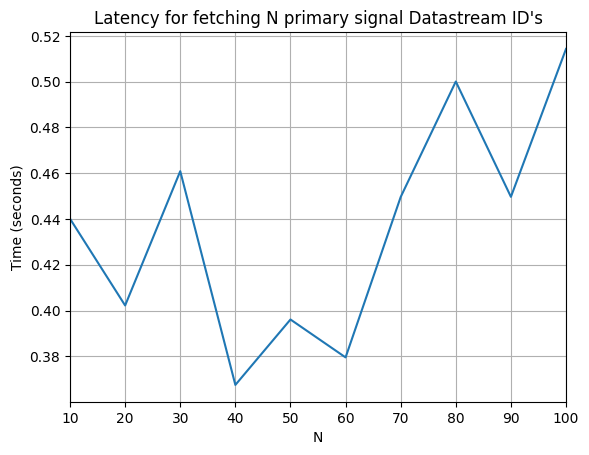

In [29]:
import matplotlib.pyplot as plt

plt.plot(n_keys, avg_times)
plt.xlabel("N")
plt.ylabel("Time (seconds)")
plt.xlim(10, 100)
plt.title("Latency for fetching N primary signal Datastream ID's")
plt.grid()
plt.show()